# Predicting Flight Departure Delays using Machine Learning

**Setornam Anyormi & Akwasi Nyarko** · Intro. to A.I. · October 29th 2026

**Live dashboard:** https://akwasinyarko.github.io/Flight_Delay_Prediction/ ·
**Repository:** https://github.com/AkwasiNyarko/Flight_Delay_Prediction

---

**Question.** About an hour before departure, can we predict whether a flight will leave **15 minutes or more late**
(the U.S. Department of Transportation's definition of a delay)?

**Data.** Every domestic departure from New York's three airports (JFK, LGA, EWR) in **2023**: U.S. Bureau of
Transportation Statistics on-time records, NOAA hourly airport weather, and the FAA aircraft registry
(the *nycflights23* dataset).

**Approach.** 22 inputs known before take-off, a time-based train/validation/test split, three models
(Logistic Regression, Random Forest, XGBoost) compared against a naive baseline, tuning on validation days only,
and an export of the final XGBoost model so it runs in a web browser.

This notebook contains all of the project's code and runs end to end (about 4 minutes).

### Contents
1. Setup
2. Data: loading, cleaning and joining
3. Exploratory data analysis
4. Feature engineering
5. Time-based train / validation / test split
6. Models and training
7. Hyperparameter tuning (validation days only)
8. Evaluation: ROC curves, confusion matrix, ablation, feature importance
9. Demonstration: predictions on real test flights
10. Exporting the model to the browser, with a parity check
11. Conclusions
12. References

## 1. Setup

Libraries, fixed settings, and the list of model inputs. Every input is known **before** departure;
columns only known afterwards (actual departure time, delay, arrival) are listed separately so we can check
they never leak into the model.

In [1]:
import io, json, math, time, urllib.request, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn, xgboost
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | xgboost 3.4.1


In [2]:
RANDOM_STATE = 42
YEAR = 2023
DELAY_THRESHOLD_MIN = 15            # U.S. DOT definition of a delayed departure

# Time-based split inside every month (day of month)
TRAIN_DAYS, VAL_DAYS, TEST_DAYS = (1, 17), (18, 21), (22, 31)

# Inputs known before departure
NUMERIC = ["sched_dep_hour", "day_of_week", "month", "distance", "plane_age", "seats",
           "temp", "dewp", "humid", "wind_speed", "wind_gust", "precip", "pressure", "visib",
           "origin_hourly_volume", "carrier_hour_volume", "days_to_holiday"]
REALTIME = ["origin_recent_delay", "origin_recent_delay_rate"]   # airport state ~1 hour before departure
CATEGORICAL = ["carrier", "origin", "dest_grouped"]
MODEL_NUMERIC = NUMERIC + REALTIME
MODEL_FEATURES = MODEL_NUMERIC + CATEGORICAL

TOP_N_DEST = 30          # the 30 busiest destinations get their own category, the rest are "OTHER"
RECENT_LAGS = (2, 3)     # look at flights scheduled 2 and 3 hours earlier

# Known only AFTER departure: must never be model inputs
LEAKY_COLUMNS = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time", "delayed"]
assert not set(LEAKY_COLUMNS) & set(MODEL_FEATURES)
print(f"{len(MODEL_FEATURES)} model inputs: {len(MODEL_NUMERIC)} numeric, {len(CATEGORICAL)} categorical")

22 model inputs: 19 numeric, 3 categorical


## 2. Data: loading, cleaning and joining

The five tables come from *nycflights23* (Ismay, Couch & Wickham), which packages the official BTS, NOAA and FAA
records for 2023. The notebook reads them from the repository's `data/` folder, or downloads them from the
project's GitHub repository if that folder isn't next to the notebook.

In [3]:
DATA_DIR = Path("data")
RAW_URL = "https://raw.githubusercontent.com/AkwasiNyarko/Flight_Delay_Prediction/main/data/"
FILES = {"flights": "flights.csv.zip", "weather": "weather.csv", "planes": "planes.csv",
         "airlines": "airlines.csv", "airports": "airports.csv"}

def read_table(name):
    fname = FILES[name]
    local = DATA_DIR / fname
    if local.exists():
        return pd.read_csv(local)
    print(f"  downloading {fname} ...")
    raw = urllib.request.urlopen(RAW_URL + fname).read()
    return pd.read_csv(io.BytesIO(raw), compression="zip" if fname.endswith(".zip") else None)

tables = {name: read_table(name) for name in FILES}
for name, t in tables.items():
    print(f"{name:9s} {t.shape[0]:>8,} rows x {t.shape[1]:>2} columns")
tables["flights"].head(3)

flights    435,352 rows x 19 columns
weather     26,207 rows x 15 columns
planes       4,840 rows x  9 columns
airlines        14 rows x  2 columns
airports     1,255 rows x  8 columns


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2023,1,1,1.0,2038,203.0,328.0,3,205.0,UA,628,N25201,EWR,SMF,367.0,2500.0,20.0,38.0,2023-01-01 20:00:00
1,2023,1,1,18.0,2300,78.0,228.0,135,53.0,DL,393,N830DN,JFK,ATL,108.0,760.0,23.0,0.0,2023-01-01 23:00:00
2,2023,1,1,31.0,2344,47.0,500.0,426,34.0,B6,371,N807JB,JFK,BQN,190.0,1576.0,23.0,44.0,2023-01-01 23:00:00


**Data quality check.** Flights and weather are joined on airport and hour, so both tables must use the same
clock. Both store New York local time: each table's `hour` column agrees with its timestamp.

In [4]:
f, w = tables["flights"], tables["weather"]
print("flights: hour column matches timestamp:", (pd.to_datetime(f.time_hour).dt.hour == f.hour).mean())
print("weather: hour column matches timestamp:", (pd.to_datetime(w.time_hour).dt.hour == w.hour).mean())
print(f"scheduled flights: {len(f):,} | cancelled (no departure delay recorded): {f.dep_delay.isna().sum():,}")

flights: hour column matches timestamp: 1.0
weather: hour column matches timestamp: 1.0
scheduled flights: 435,352 | cancelled (no departure delay recorded): 10,738


**Cleaning and joining.** Cancelled flights are a different problem and are dropped. The label is
`delayed = 1` when the departure delay is 15 minutes or more. Each flight gets the weather at its origin airport
for its scheduled hour, and its aircraft's build year and seat count.

In [5]:
def build_flight_table(tables):
    df = tables["flights"].copy()
    df = df.dropna(subset=["dep_delay"])                                  # drop cancelled flights
    df["time_hour"] = pd.to_datetime(df["time_hour"])
    df["delayed"] = (df["dep_delay"] >= DELAY_THRESHOLD_MIN).astype(int)  # the label

    w = tables["weather"].copy()
    w["time_hour"] = pd.to_datetime(w["time_hour"])
    w = w.drop(columns=["year", "month", "day", "hour"]).drop_duplicates(subset=["origin", "time_hour"])
    df = df.merge(w, on=["origin", "time_hour"], how="left")            # weather at origin, that hour

    p = tables["planes"][["tailnum", "year", "seats"]].rename(columns={"year": "plane_year"})
    return df.merge(p, on="tailnum", how="left")                        # aircraft details

flights = build_flight_table(tables)
print(f"departed flights: {len(flights):,}")
print(f"matched to a weather record: {flights['temp'].notna().mean():.1%}")
print(f"matched to the aircraft registry: {flights['plane_year'].notna().mean():.1%}")
print(f"share delayed 15+ min: {flights['delayed'].mean():.1%}")
print(f"average delay of delayed flights: {flights.loc[flights.delayed == 1, 'dep_delay'].mean():.0f} min")

departed flights: 424,614
matched to a weather record: 99.8%
matched to the aircraft registry: 96.0%
share delayed 15+ min: 21.6%
average delay of delayed flights: 76 min


## 3. Exploratory data analysis

Before modelling: how does the delay rate vary with time of day, season, airline and weather?

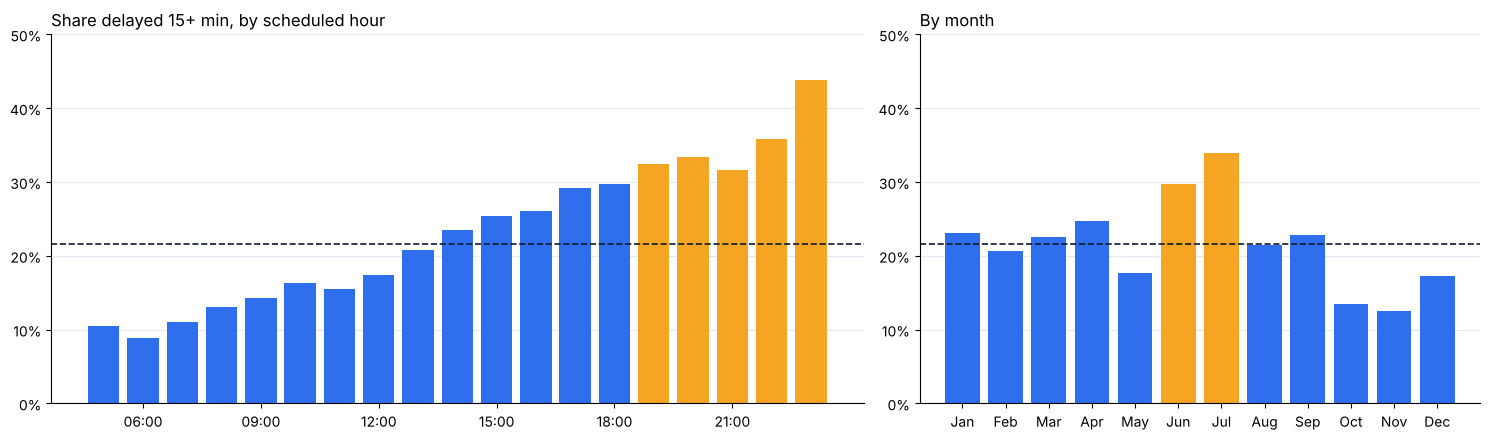

06:00 departures: 8.9% delayed  |  23:00 departures: 43.8% delayed
worst month: Jul (34.0%)  |  best: Nov (12.5%)


In [6]:
NAVY, BLUE, AMBER, GREY = "#0F1B2D", "#2F6FED", "#F5A524", "#AEB6C2"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
overall = flights["delayed"].mean()
flights["sched_hour"] = flights["sched_dep_time"] // 100

def pct(ax, top):
    ax.set_ylim(0, top); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#E6EAF0"); ax.set_axisbelow(True)

fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.45, 1]})
by_hour = flights.groupby("sched_hour")["delayed"].mean()
a.bar(by_hour.index, by_hour.values, color=[AMBER if r >= .30 else BLUE for r in by_hour])
a.axhline(overall, color=NAVY, ls="--", lw=1.2); a.set_title("Share delayed 15+ min, by scheduled hour", loc="left")
a.set_xticks(range(6, 24, 3), [f"{h:02d}:00" for h in range(6, 24, 3)]); pct(a, .5)
by_month = flights.groupby("month")["delayed"].mean()
b.bar(MONTHS, by_month.values, color=[AMBER if r >= .28 else BLUE for r in by_month])
b.axhline(overall, color=NAVY, ls="--", lw=1.2); b.set_title("By month", loc="left"); pct(b, .5)
plt.tight_layout(); plt.show()
print(f"06:00 departures: {by_hour[6]:.1%} delayed  |  23:00 departures: {by_hour[23]:.1%} delayed")
print(f"worst month: {MONTHS[by_month.idxmax()-1]} ({by_month.max():.1%})  |  best: {MONTHS[by_month.idxmin()-1]} ({by_month.min():.1%})")

Delays **build through the day**: each late aircraft passes its delay to its next flight (delay propagation).
Summer (thunderstorms, peak travel) is worst.

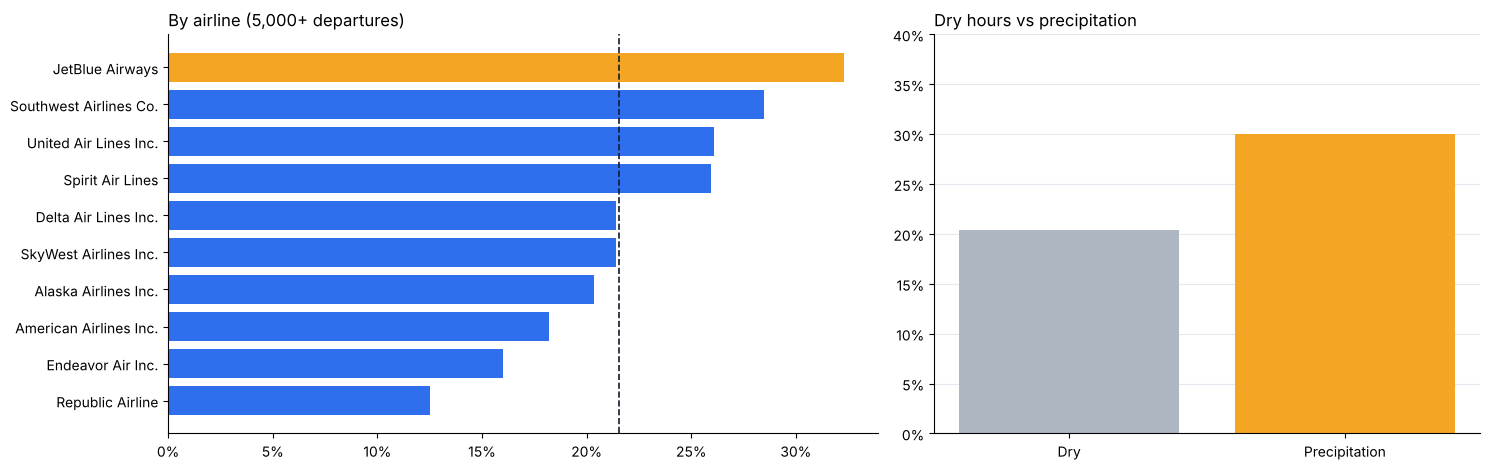

         delay_rate  flights                 airline
carrier                                             
B6            0.323    64622         JetBlue Airways
WN            0.285    12105  Southwest Airlines Co.
UA            0.261    77810   United Air Lines Inc.
NK            0.259    14827        Spirit Air Lines
DL            0.214    60616    Delta Air Lines Inc.
OO            0.214     6214   SkyWest Airlines Inc.
AS            0.203     7774    Alaska Airlines Inc.
AA            0.182    39940  American Airlines Inc.
9E            0.160    52380       Endeavor Air Inc.
YX            0.125    85723        Republic Airline

dry: 20.4% delayed | precipitation: 30.0% delayed


In [7]:
names = dict(zip(tables["airlines"].carrier, tables["airlines"].name))
by_air = flights.groupby("carrier")["delayed"].agg(["mean", "size"])
by_air = by_air[by_air["size"] >= 5000].sort_values("mean")
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
a.barh([names[c] for c in by_air.index], by_air["mean"], color=[AMBER if r >= .30 else BLUE for r in by_air["mean"]])
a.axvline(overall, color=NAVY, ls="--", lw=1.2); a.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
a.set_title("By airline (5,000+ departures)", loc="left"); a.spines[["top", "right"]].set_visible(False)
wet = flights.assign(cond=np.where(flights["precip"].fillna(0) > 0, "Precipitation", "Dry")).groupby("cond")["delayed"].mean()
b.bar(wet.index, wet.values, color=[GREY, AMBER]); b.set_title("Dry hours vs precipitation", loc="left"); pct(b, .4)
plt.tight_layout(); plt.show()
print(by_air.assign(airline=[names[c] for c in by_air.index]).rename(columns={"mean": "delay_rate", "size": "flights"})
      .round(3).iloc[::-1].to_string())
print(f"\ndry: {wet['Dry']:.1%} delayed | precipitation: {wet['Precipitation']:.1%} delayed")

## 4. Feature engineering

Twenty-two inputs, all available about an hour before departure:

| Group | Inputs |
| --- | --- |
| Schedule | departure hour, day of week, month, days to the nearest federal holiday |
| Flight | airline, origin airport, destination (top 30 or "OTHER"), distance |
| Aircraft | age, seats |
| Weather at origin | temperature, dew point, humidity, wind speed and gusts, precipitation, pressure, visibility |
| Congestion | departures scheduled at the airport that hour, and by that airline |
| **Airport state** | average delay and delay rate of flights scheduled **2–3 hours earlier** at the same airport |

The last group captures **delay propagation**, the same idea as the network delay state used by
Rebollo & Balakrishnan (2014).

In [8]:
def nth_weekday(year, month, weekday, n):
    days = pd.date_range(f"{year}-{month:02d}-01", periods=pd.Timestamp(year, month, 1).days_in_month)
    days = days[days.dayofweek == weekday]
    return days[n - 1] if n > 0 else days[-1]

def us_federal_holidays(year):
    # Actual dates. The dashboard's JavaScript uses the same rules (docs/js/app.js).
    dates = [pd.Timestamp(year, 1, 1), nth_weekday(year, 1, 0, 3), nth_weekday(year, 2, 0, 3),
             nth_weekday(year, 5, 0, -1), pd.Timestamp(year, 7, 4), nth_weekday(year, 9, 0, 1),
             nth_weekday(year, 10, 0, 2), pd.Timestamp(year, 11, 11), nth_weekday(year, 11, 3, 4),
             pd.Timestamp(year, 12, 25)]
    if year >= 2021:
        dates.append(pd.Timestamp(year, 6, 19))      # Juneteenth
    return pd.DatetimeIndex(sorted(dates))

def days_to_nearest(dates, holidays):
    d = dates.values[:, None] - holidays.values[None, :]
    return np.abs(d.astype("timedelta64[D]").astype(int)).min(axis=1)

print("2023 federal holidays:", ", ".join(d.strftime("%b %d") for d in us_federal_holidays(YEAR)))

2023 federal holidays: Jan 01, Jan 16, Feb 20, May 29, Jun 19, Jul 04, Sep 04, Oct 09, Nov 11, Nov 23, Dec 25


In [9]:
KEYS = ["origin", "year", "month", "day", "sched_dep_hour"]

def recent_airport_delays(df):
    # Average delay and delay rate of flights scheduled 2-3 hours earlier at the same airport.
    # Shifting the hourly table forward by each lag lines past hours up with later flights.
    hourly = (df.groupby(KEYS).agg(sum_delay=("dep_delay", "sum"), n=("dep_delay", "size"),
                                    n_late=("delayed", "sum")).reset_index())
    shifted = []
    for lag in RECENT_LAGS:
        h = hourly.copy()
        h["sched_dep_hour"] += lag
        shifted.append(h)
    recent = pd.concat(shifted).groupby(KEYS)[["sum_delay", "n", "n_late"]].sum().reset_index()
    recent["origin_recent_delay"] = recent["sum_delay"] / recent["n"]
    recent["origin_recent_delay_rate"] = recent["n_late"] / recent["n"]
    return recent[KEYS + ["origin_recent_delay", "origin_recent_delay_rate"]]

def engineer_features(df):
    df = df.copy()
    df["sched_dep_hour"] = df["sched_dep_time"] // 100
    date = pd.to_datetime(df[["year", "month", "day"]])
    df["day_of_week"] = date.dt.dayofweek                       # 0 = Monday
    df["plane_age"] = YEAR - df["plane_year"]
    # congestion: scheduled departures in the same hour
    df["origin_hourly_volume"] = df.groupby(["origin", "time_hour"])["flight"].transform("count")
    df["carrier_hour_volume"] = df.groupby(["carrier", "origin", "time_hour"])["flight"].transform("count")
    df["days_to_holiday"] = days_to_nearest(date, us_federal_holidays(YEAR))
    df = df.merge(recent_airport_delays(df), on=KEYS, how="left")
    top = list(df["dest"].value_counts().nlargest(TOP_N_DEST).index)
    df["dest_grouped"] = np.where(df["dest"].isin(top), df["dest"], "OTHER")
    return df

t0 = time.time()
df = engineer_features(flights.drop(columns=["sched_hour"]))
print(f"features built for {len(df):,} flights in {time.time()-t0:.1f}s")
df[MODEL_FEATURES + ["delayed"]].head()

features built for 424,614 flights in 0.8s


,sched_dep_hour,day_of_week,month,distance,plane_age,seats,temp,dewp,humid,wind_speed,...,visib,origin_hourly_volume,carrier_hour_volume,days_to_holiday,origin_recent_delay,origin_recent_delay_rate,carrier,origin,dest_grouped,delayed
0,20,6,1,2500.0,24.0,149.0,57.0,33.0,40.28,10.35702,...,10.0,24,15,0,23.208333,0.500000,UA,EWR,OTHER,1
1,23,6,1,760.0,9.0,222.0,47.0,38.0,70.73,0.00000,...,10.0,3,1,0,31.904762,0.428571,DL,JFK,ATL,1
2,23,6,1,1576.0,11.0,200.0,47.0,38.0,70.73,0.00000,...,10.0,3,2,0,31.904762,0.428571,B6,JFK,OTHER,1
3,21,6,1,636.0,17.0,20.0,52.0,33.0,48.34,8.05546,...,10.0,12,8,0,15.108108,0.243243,B6,JFK,CHS,1
4,20,6,1,488.0,24.0,149.0,57.0,33.0,40.28,10.35702,...,10.0,24,15,0,23.208333,0.500000,UA,EWR,DTW,1


**Checks.** The joins must not duplicate flights, and the airport-state feature must use only *earlier*
flights. We recompute it by hand for one flight.

In [10]:
assert len(df) == len(flights), "a join duplicated flights"

row = df.dropna(subset=["origin_recent_delay"]).sample(1, random_state=0).iloc[0]
same_day = df[(df.origin == row.origin) & (df.month == row.month) & (df.day == row.day)]
earlier = same_day[same_day.sched_dep_hour.isin([row.sched_dep_hour - lag for lag in RECENT_LAGS])]
assert abs(earlier.dep_delay.mean() - row.origin_recent_delay) < 1e-9
print(f"{row.origin} {int(row.month)}/{int(row.day)} {int(row.sched_dep_hour)}:00 flight -> "
      f"{len(earlier)} flights 2-3 h earlier averaged {earlier.dep_delay.mean():.1f} min late (matches the feature)")
print("missing values among inputs:")
print(df[MODEL_FEATURES].isna().mean().loc[lambda s: s > 0].round(3).to_string())

EWR 1/20 13:00 flight -> 43 flights 2-3 h earlier averaged 1.3 min late (matches the feature)
missing values among inputs:
plane_age                   0.040
seats                       0.022
temp                        0.002
dewp                        0.002
humid                       0.002
wind_speed                  0.042
wind_gust                   0.042
precip                      0.002
pressure                    0.002
visib                       0.003
origin_recent_delay         0.077
origin_recent_delay_rate    0.077


## 5. Time-based train / validation / test split

A random split would let the model train on flights from the same hour and airport it is tested on, which
leaks information. Instead, **inside every month**: days 1–17 train the model, days 18–21 tune it, and
days 22–31 are the final test. Every season is represented in training, and every test flight comes after its
training data.

In [11]:
def between(frame, lo_hi):
    return frame[(frame["day"] >= lo_hi[0]) & (frame["day"] <= lo_hi[1])]

train, val, test = between(df, TRAIN_DAYS), between(df, VAL_DAYS), between(df, TEST_DAYS)
assert train.day.max() < val.day.min() and val.day.max() < test.day.min()
assert len(train) + len(val) + len(test) == len(df) and set(train.month) == set(range(1, 13))
y_train, y_val, y_test = train["delayed"], val["delayed"], test["delayed"]
pd.DataFrame({"days": [f"{TRAIN_DAYS[0]}-{TRAIN_DAYS[1]}", f"{VAL_DAYS[0]}-{VAL_DAYS[1]}", f"{TEST_DAYS[0]}-{TEST_DAYS[1]}"],
              "flights": [len(train), len(val), len(test)],
              "delay rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).style.format({"flights": "{:,}", "delay rate": "{:.1%}"})

,days,flights,delay rate
train,1-17,"237,490",21.7%
validation,18-21,"57,322",19.5%
test,22-31,"129,802",22.2%


## 6. Models and training

Three models share the same preprocessing: missing numbers are filled with the training median and categories
are one-hot encoded (Logistic Regression also standardises the numbers). Because only about 22% of flights are
delayed, each model weights the delayed class more heavily. The decision **threshold** is then chosen to
maximise F1 on the **validation** days, never on the test days.

The XGBoost settings below were chosen by the tuning experiment in Section 7.

In [12]:
XGB_PARAMS = dict(n_estimators=800, max_depth=5, learning_rate=0.05, min_child_weight=10,
                  subsample=0.8, colsample_bytree=0.8)

def build_preprocessor(scale, numeric):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    # dense output, so the browser version (Section 10) sees exactly the matrix XGBoost saw
    return ColumnTransformer([("num", Pipeline(num_steps), numeric),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
                             sparse_threshold=0)

def build_models(pos_weight, numeric, xgb_params=XGB_PARAMS):
    return {
        "Logistic Regression": Pipeline([("prep", build_preprocessor(True, numeric)),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        "Random Forest": Pipeline([("prep", build_preprocessor(False, numeric)),
            ("clf", RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=20,
                                           class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
        "XGBoost": Pipeline([("prep", build_preprocessor(False, numeric)),
            ("clf", XGBClassifier(**xgb_params, scale_pos_weight=pos_weight, eval_metric="auc",
                                  n_jobs=-1, random_state=RANDOM_STATE))]),
    }

def tune_threshold(y, prob):
    grid = np.arange(0.20, 0.81, 0.01)
    return float(round(grid[np.argmax([f1_score(y, prob >= t) for t in grid])], 2))

def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {"model": name, "threshold": round(float(threshold), 2), "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, prob) if np.std(prob) > 0 else 0.5}

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"class weight for delayed flights: {pos_weight:.2f}")

class weight for delayed flights: 3.60


In [13]:
results = [evaluate("Baseline (always on time)", y_test, np.zeros(len(y_test)))]
probs, fitted = {}, {}
for name, model in build_models(pos_weight, MODEL_NUMERIC).items():
    t0 = time.time()
    model.fit(train[MODEL_FEATURES], y_train)
    t = tune_threshold(y_val, model.predict_proba(val[MODEL_FEATURES])[:, 1])
    p = model.predict_proba(test[MODEL_FEATURES])[:, 1]
    probs[name], fitted[name] = p, (model, t)
    results.append(evaluate(name, y_test, p, t))
    print(f"{name:20s} trained in {time.time()-t0:5.1f}s, threshold {t:.2f}")

# Ablation: the same XGBoost without the live airport-state features
base = NUMERIC + CATEGORICAL
abl = build_models(pos_weight, NUMERIC)["XGBoost"].fit(train[base], y_train)
t_abl = tune_threshold(y_val, abl.predict_proba(val[base])[:, 1])
results.append(evaluate("XGBoost, schedule + weather only", y_test, abl.predict_proba(test[base])[:, 1], t_abl))

res = pd.DataFrame(results).set_index("model")
res.style.format({"threshold": "{:.2f}", "accuracy": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}",
                  "f1": "{:.3f}", "roc_auc": "{:.3f}"}).highlight_max(subset=["f1", "roc_auc"], color="#FDE7D6")

Logistic Regression  trained in   5.4s, threshold 0.52


Random Forest        trained in  43.1s, threshold 0.50


XGBoost              trained in  18.6s, threshold 0.51


,threshold,accuracy,precision,recall,f1,roc_auc
model,,,,,,
Baseline (always on time),0.50,0.778,0.000,0.000,0.000,0.500
Logistic Regression,0.52,0.713,0.405,0.616,0.488,0.740
Random Forest,0.50,0.726,0.420,0.622,0.501,0.755
XGBoost,0.51,0.723,0.417,0.626,0.501,0.755
"XGBoost, schedule + weather only",0.47,0.674,0.369,0.665,0.475,0.732


**Reading the table.**
- The baseline has the **highest accuracy** (77.8%) yet catches **no** delays. With imbalanced classes,
  accuracy is misleading, so we judge on **F1** and **ROC-AUC**.
- Random Forest and XGBoost tie at ROC-AUC 0.755. XGBoost is deployed because its trees export cleanly
  to the browser (Section 10).
- Removing the live airport-state features drops XGBoost's ROC-AUC from 0.755 to 0.732.

## 7. Hyperparameter tuning (validation days only)

Six XGBoost settings, each scored by ROC-AUC on the **validation** days. The test days are never used to choose
settings.

In [14]:
grid = [dict(n_estimators=400, max_depth=7, learning_rate=0.05, min_child_weight=1),
        dict(n_estimators=600, max_depth=6, learning_rate=0.05, min_child_weight=5),
        dict(n_estimators=800, max_depth=5, learning_rate=0.05, min_child_weight=10),
        dict(n_estimators=600, max_depth=8, learning_rate=0.03, min_child_weight=20),
        dict(n_estimators=1000, max_depth=6, learning_rate=0.03, min_child_weight=10),
        dict(n_estimators=500, max_depth=9, learning_rate=0.03, min_child_weight=50)]
rows = []
for g in grid:
    m = build_models(pos_weight, MODEL_NUMERIC, {**g, "subsample": 0.8, "colsample_bytree": 0.8})["XGBoost"]
    m.fit(train[MODEL_FEATURES], y_train)
    rows.append({**g, "val_auc": roc_auc_score(y_val, m.predict_proba(val[MODEL_FEATURES])[:, 1])})
tuning = pd.DataFrame(rows).sort_values("val_auc", ascending=False).reset_index(drop=True)
best = tuning.iloc[0]
assert int(best.n_estimators) == XGB_PARAMS["n_estimators"] and int(best.max_depth) == XGB_PARAMS["max_depth"]
print(f"best minus worst validation AUC: {tuning.val_auc.max() - tuning.val_auc.min():.4f}")
tuning.style.format({"learning_rate": "{:.2f}", "val_auc": "{:.4f}"})

best minus worst validation AUC: 0.0024


,n_estimators,max_depth,learning_rate,min_child_weight,val_auc
0,800,5,0.05,10,0.7396
1,500,9,0.03,50,0.7393
2,1000,6,0.03,10,0.7391
3,600,8,0.03,20,0.7385
4,600,6,0.05,5,0.7384
5,400,7,0.05,1,0.7372


The best setting (800 trees of depth 5) is the one used in Section 6. Tuning moved validation AUC by only
about **0.002**, while adding the airport-state features moved test AUC by **0.023**: the limit is the
information in the data, not the model's settings.

## 8. Evaluation

### ROC curves

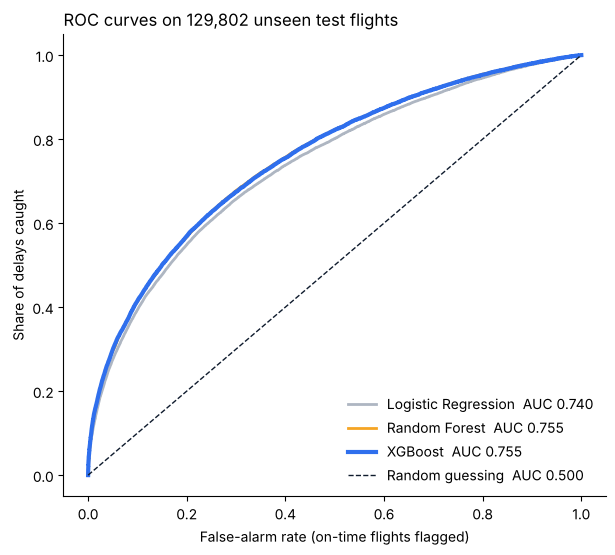

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
for (name, p), c, lw in zip(probs.items(), [GREY, AMBER, BLUE], [2, 2, 3]):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=c, lw=lw, label=f"{name}  AUC {roc_auc_score(y_test, p):.3f}")
ax.plot([0, 1], [0, 1], "--", color=NAVY, lw=1, label="Random guessing  AUC 0.500")
ax.set_xlabel("False-alarm rate (on-time flights flagged)"); ax.set_ylabel("Share of delays caught")
ax.set_title(f"ROC curves on {len(test):,} unseen test flights", loc="left"); ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.show()

### Confusion matrix (XGBoost, at its tuned threshold)

In [16]:
xgb, threshold = fitted["XGBoost"]
cm = confusion_matrix(y_test, (probs["XGBoost"] >= threshold).astype(int))
(tn, fp), (fn, tp) = cm
display(pd.DataFrame(cm, index=["left on time", "left 15+ min late"], columns=["predicted on time", "predicted delayed"])
        .style.format("{:,}"))
print(f"delays caught (recall): {tp/(tp+fn):.1%}  |  warnings that were right (precision): {tp/(tp+fp):.1%}"
      f"  |  base rate: {y_test.mean():.1%}")
print(f"on-time flights wrongly warned: {fp/(fp+tn):.1%}")

,predicted on time,predicted delayed
left on time,"75,759","25,230"
left 15+ min late,"10,772","18,041"


delays caught (recall): 62.6%  |  warnings that were right (precision): 41.7%  |  base rate: 22.2%
on-time flights wrongly warned: 25.0%


### Feature importance (permutation)

Shuffle one input at a time on 20,000 test flights and measure how far ROC-AUC falls. Unlike XGBoost's built-in
"gain" scores, this works on the original inputs, so one-hot encoded categories (airline, destination) are not
split into many small pieces.

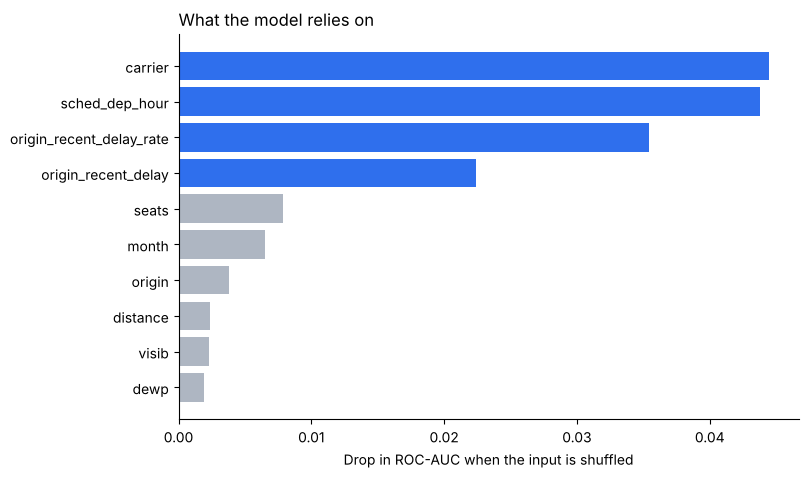

,AUC drop
carrier,0.0445
sched_dep_hour,0.0438
origin_recent_delay_rate,0.0354
origin_recent_delay,0.0224
seats,0.0079
month,0.0065
origin,0.0038
distance,0.0024


In [17]:
sample = test[MODEL_FEATURES].sample(20000, random_state=RANDOM_STATE)
r = permutation_importance(xgb, sample, y_test.loc[sample.index], scoring="roc_auc",
                           n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=MODEL_FEATURES).sort_values(ascending=False)
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[BLUE if v >= .015 else GREY for v in top.values])
ax.set_xlabel("Drop in ROC-AUC when the input is shuffled"); ax.set_title("What the model relies on", loc="left")
ax.spines[["top", "right"]].set_visible(False); plt.show()
imp.head(8).round(4).to_frame("AUC drop")

## 9. Demonstration: predictions on real test flights

Six real flights from the test set (unseen during training), chosen to show each kind of outcome: delays caught,
on-time flights correctly cleared, a false alarm and a missed delay.

In [18]:
scored = test.assign(p=probs["XGBoost"])
rng = np.random.default_rng(3)
def pick(mask, n):
    sub = scored[mask]
    return sub.iloc[rng.choice(len(sub), n, replace=False)]
demo = pd.concat([pick((scored.p >= .75) & (scored.dep_delay >= 45), 2).assign(outcome="Delay caught"),
                  pick((scored.p < .20) & (scored.dep_delay <= 0), 2).assign(outcome="Correctly on time"),
                  pick((scored.p >= .55) & (scored.p < .70) & (scored.dep_delay <= 0), 1).assign(outcome="False alarm"),
                  pick((scored.p < .35) & (scored.dep_delay >= 30), 1).assign(outcome="Delay missed")])
demo.assign(flight=demo.carrier + " " + demo.flight.astype(str), route=demo.origin + " -> " + demo.dest,
            date=demo.month.astype(str) + "/" + demo.day.astype(str),
            departs=demo.sched_dep_time.map(lambda s: f"{s//100:02d}:{s%100:02d}"),
            risk=(demo.p * 100).round().astype(int).astype(str) + "%",
            model_says=np.where(demo.p >= threshold, "Delayed", "On time"),
            actual=demo.dep_delay.astype(int).astype(str) + " min")[
    ["flight", "date", "route", "departs", "risk", "model_says", "actual", "outcome"]].reset_index(drop=True)

,flight,date,route,departs,risk,model_says,actual,outcome
0,NK 704,2/24,EWR -> MCO,22:05,79%,Delayed,78 min,Delay caught
1,B6 498,8/25,JFK -> BNA,17:51,86%,Delayed,81 min,Delay caught
2,YX 1601,5/23,LGA -> DCA,20:30,19%,On time,-7 min,Correctly on time
3,YX 1094,4/24,LGA -> STL,06:25,17%,On time,-9 min,Correctly on time
4,9E 1601,9/30,JFK -> SYR,15:20,63%,Delayed,-3 min,False alarm
5,YX 916,8/25,EWR -> RIC,08:27,29%,On time,58 min,Delay missed


**What-if: the same flight at different times.** JetBlue, JFK → Orlando on Wednesday 20 December 2023, with
typical weather and airport conditions for that airport and hour (the dashboard's default example).

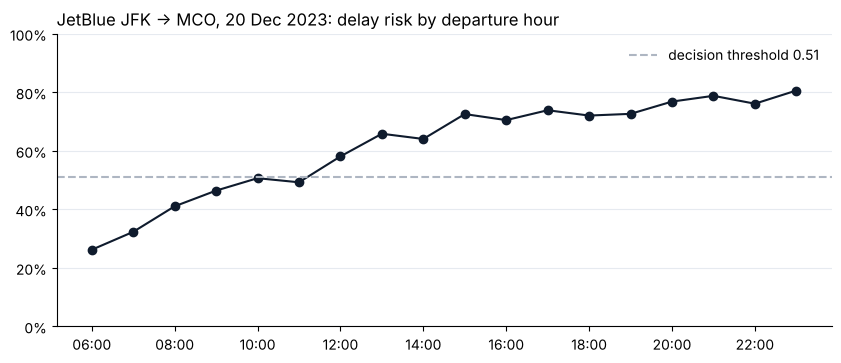

07:00 -> 32%   19:00 -> 73%


In [19]:
def typical_flight(carrier, origin, dest, month, day, hour):
    ref = df[(df.origin == origin) & (df.month == month)]
    at_hour = df[(df.origin == origin) & (df.sched_dep_hour == hour)]
    rec = {c: ref[c].median() for c in ["temp", "dewp", "humid", "wind_speed", "pressure", "visib"]}
    rec.update(sched_dep_hour=hour, day_of_week=pd.Timestamp(YEAR, month, day).dayofweek, month=month,
               distance=df[(df.origin == origin) & (df.dest == dest)].distance.median(),
               plane_age=df[df.carrier == carrier].plane_age.median(), seats=df[df.carrier == carrier].seats.median(),
               wind_gust=np.nan, precip=0.0, origin_hourly_volume=at_hour.origin_hourly_volume.median(),
               carrier_hour_volume=at_hour[at_hour.carrier == carrier].carrier_hour_volume.median(),
               days_to_holiday=int(days_to_nearest(pd.Series([pd.Timestamp(YEAR, month, day)]), us_federal_holidays(YEAR))[0]),
               origin_recent_delay=at_hour.origin_recent_delay.median(),
               origin_recent_delay_rate=at_hour.origin_recent_delay_rate.median(),
               carrier=carrier, origin=origin, dest_grouped=dest if dest in set(df.dest_grouped) else "OTHER")
    return rec

hours = range(6, 24)
risk = [xgb.predict_proba(pd.DataFrame([typical_flight("B6", "JFK", "MCO", 12, 20, h)]))[0, 1] for h in hours]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(list(hours), risk, color=NAVY, marker="o")
ax.axhline(threshold, color=GREY, ls="--", label=f"decision threshold {threshold:.2f}")
ax.set_xticks(list(hours)[::2], [f"{h:02d}:00" for h in list(hours)[::2]]); pct(ax, 1)
ax.set_title("JetBlue JFK -> MCO, 20 Dec 2023: delay risk by departure hour", loc="left"); ax.legend(frameon=False); plt.show()
print(f"07:00 -> {risk[1]:.0%}   19:00 -> {risk[13]:.0%}")

The dashboard's predictor fills unset inputs with typical values computed slightly differently (for example
quartiles of the airport state instead of medians), so its numbers can differ by a few points from this cell.
The pattern is the same: evening departures inherit the day's delays.

## 10. Exporting the model to the browser, with a parity check

GitHub Pages can only serve static files, so the dashboard cannot run Python. Instead we export everything the
model needs to a JSON file:
- the training medians and one-hot categories (the preprocessing), and
- all 800 decision trees as flat arrays: split feature, split value, yes/no child and leaf value.

XGBoost compares inputs as 32-bit floats, so numbers are written at full float32 precision. Rounding them (an
early version wrote 6 decimals) pushed some values across a split and changed 89 of 1,000 predictions.

In [20]:
def f32(x):
    return float(str(np.float32(x)))        # shortest decimal that round-trips to the same float32

def base_margin(booster):
    p = float(str(json.loads(booster.save_config())["learner"]["learner_model_param"]["base_score"]).strip("[]"))
    return math.log(p / (1 - p))            # base_score is a probability; trees add to its logit

def flatten_tree(tree):
    nodes, stack = {}, [tree]
    while stack:
        n = stack.pop(); nodes[n["nodeid"]] = n; stack.extend(n.get("children", []))
    size = max(nodes) + 1
    f, t, y, no, v = [-1] * size, [0.0] * size, [0] * size, [0] * size, [0.0] * size
    for i, n in nodes.items():
        if "leaf" in n:
            v[i] = f32(n["leaf"])
        else:
            f[i], t[i], y[i], no[i] = int(n["split"].lstrip("f")), f32(n["split_condition"]), n["yes"], n["no"]
    return {"f": f, "t": t, "y": y, "n": no, "v": v}

def model_spec(pipe, threshold):
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    booster = clf.get_booster()
    return {"numeric": MODEL_NUMERIC,
            "medians": [float(m) for m in prep.named_transformers_["num"].named_steps["impute"].statistics_],
            "categorical": [{"name": n, "categories": [str(c) for c in cats]}
                            for n, cats in zip(CATEGORICAL, prep.named_transformers_["cat"].categories_)],
            "base_margin": base_margin(booster), "threshold": threshold,
            "trees": [flatten_tree(json.loads(t)) for t in booster.get_dump(dump_format="json")]}

spec = model_spec(xgb, threshold)
Path("model.json").write_text(json.dumps(spec, separators=(",", ":")))
print(f"{len(spec['trees'])} trees exported to model.json ({Path('model.json').stat().st_size/1e6:.2f} MB)")

800 trees exported to model.json (0.95 MB)


The browser evaluates the trees with this JavaScript (`docs/js/model.js` in the repository):

```javascript
DelayModel.prototype.vectorize = function (record) {
  var x = new Float32Array(this.nFeatures);                 // float32, like XGBoost
  for (var i = 0; i < this.numeric.length; i++) {          // numeric: missing -> training median
    var v = record[this.numeric[i]];
    x[i] = (v === null || v === undefined || v === "" || isNaN(+v)) ? this.medians[i] : +v;
  }
  var offset = this.numeric.length;                         // categorical: one-hot, unknown -> all zeros
  for (i = 0; i < this.categorical.length; i++) {
    var idx = this.catIndex[i][String(record[this.categorical[i].name])];
    if (idx !== undefined) x[offset + idx] = 1;
    offset += this.categorical[i].categories.length;
  }
  return x;
};

DelayModel.prototype.margin = function (x) {
  var s = this.baseMargin;
  for (var k = 0; k < this.trees.length; k++) {             // walk each of the 800 trees
    var t = this.trees[k], node = 0;
    while (t.f[node] >= 0)                                  // until a leaf
      node = x[t.f[node]] < t.t[node] ? t.y[node] : t.n[node];
    s += t.v[node];                                         // add the leaf value
  }
  return s;
};

DelayModel.prototype.predict = function (record) { return 1 / (1 + Math.exp(-this.margin(this.vectorize(record)))); };
```

The cell below re-implements exactly that logic in Python, using only the exported JSON, and checks it against
XGBoost on 1,000 test flights. If Node.js is installed, it also runs the real JavaScript file.

In [21]:
def json_predict(spec, rows):
    numeric, med = spec["numeric"], np.array(spec["medians"])
    cats = spec["categorical"]
    n_feat = len(numeric) + sum(len(c["categories"]) for c in cats)
    trees = [{k: np.array(v, dtype=np.float32 if k == "t" else (np.float64 if k == "v" else np.int64))
              for k, v in t.items()} for t in spec["trees"]]
    out = []
    for _, r in rows.iterrows():
        x = np.zeros(n_feat, dtype=np.float32)
        vals = r[numeric].to_numpy(dtype=float)
        x[:len(numeric)] = np.where(np.isnan(vals), med, vals)
        off = len(numeric)
        for c in cats:
            if str(r[c["name"]]) in c["categories"]:
                x[off + c["categories"].index(str(r[c["name"]]))] = 1
            off += len(c["categories"])
        s = spec["base_margin"]
        for t in trees:
            node = 0
            while t["f"][node] >= 0:
                node = t["y"][node] if x[t["f"][node]] < t["t"][node] else t["n"][node]
            s += t["v"][node]
        out.append(1 / (1 + math.exp(-s)))
    return np.array(out)

check = test.sample(1000, random_state=1)
expected = xgb.predict_proba(check[MODEL_FEATURES])[:, 1]
got = json_predict(json.loads(Path("model.json").read_text()), check[MODEL_FEATURES])
print(f"exported model vs XGBoost on 1,000 test flights: max difference {np.abs(got - expected).max():.1e}")
assert np.abs(got - expected).max() < 1e-4

import shutil, subprocess
js = Path("docs/js/model.js")
if shutil.which("node") and js.exists():
    rows = [[None if (isinstance(v, float) and math.isnan(v)) else (str(v) if n in CATEGORICAL else f32(v))
             for n, v in zip(MODEL_FEATURES, r)] for r in check[MODEL_FEATURES].itertuples(index=False)]
    Path("rows.json").write_text(json.dumps({"features": MODEL_FEATURES, "rows": rows}))
    script = ("const M=require('./docs/js/model.js'),fs=require('fs');const s=JSON.parse(fs.readFileSync('model.json'));"
              "const d=JSON.parse(fs.readFileSync('rows.json'));const m=new M(s);"
              "process.stdout.write(JSON.stringify(d.rows.map(r=>m.predictRow(d.features,r))));")
    js_probs = np.array(json.loads(subprocess.run(["node", "-e", script], capture_output=True, text=True, check=True).stdout))
    print(f"real JavaScript (docs/js/model.js) vs XGBoost: max difference {np.abs(js_probs - expected).max():.1e}")
    Path("rows.json").unlink()
else:
    print("Node.js or docs/js/model.js not found: skipped the JavaScript run (the Python check above uses the same logic).")

exported model vs XGBoost on 1,000 test flights: max difference 4.6e-07


real JavaScript (docs/js/model.js) vs XGBoost: max difference 4.6e-07


## 11. Conclusions

- **Delays are predictable enough to act on.** On 129,802 unseen 2023 flights, XGBoost reaches ROC-AUC 0.755
  and flags 63% of delays about an hour ahead. When it warns, it is right about 42% of the time, roughly twice
  the 22% base rate.
- **What drives delays:** the airline, the departure hour and the airport's recent delays. Weather adds less
  once the model knows how the airport is running.
- **Lessons learned:**
  1. *Pick the right metric.* 77.8% accuracy can mean zero skill on imbalanced data.
  2. *Data beats tuning.* Six settings changed AUC by 0.002; live airport data added 0.023.
  3. *Test like it's real.* Split by time, and check that the deployed model gives the same answers.
- **Limitations and future work:** one year and three airports; weather only at the origin; about 25% of
  on-time flights still get a warning. Next steps: all U.S. airports, tracking each aircraft's previous flight,
  live data feeds, predicting minutes of delay, and retraining yearly, since patterns drift. Our earlier 2013
  version relied most on departure hour (AUC 0.765); on 2023 data the airline matters most (Giusti et al.).

**Project outputs:** this notebook; the `flight_delay/` Python package and tests in the repository; and the live
dashboard, where the exported model runs in the browser.

## 12. References

1. Ball, M., et al. (2010). *Total Delay Impact Study*. NEXTOR, for the Federal Aviation Administration.
2. Rebollo, J. J., & Balakrishnan, H. (2014). Characterization and prediction of air traffic delays.
   *Transportation Research Part C*, 44, 231–241. doi:10.1016/j.trc.2014.04.007
3. Carvalho, L., Sternberg, A., et al. (2020). On the relevance of data science for flight delay research:
   a systematic review. *Transport Reviews*. doi:10.1080/01441647.2020.1861123
4. Yazdi, M. F., Kamel, S. R., Chabok, S. J. M., & Kheirabadi, M. (2020). Flight delay prediction based on deep
   learning and Levenberg-Marquart algorithm. *Journal of Big Data*, 7. doi:10.1186/s40537-020-00380-z
5. Kiliç, K., & Sallan, J. M. (2023). Study of delay prediction in the US airport network. *Aerospace*, 10(4), 342.
6. Giusti, L., Carvalho, L., Gomes, A. T., Coutinho, R., Soares, J., & Ogasawara, E. Analyzing flight delay
   prediction under concept drift. arXiv:2104.01720.
7. Ismay, C., Couch, S. P., & Wickham, H. *nycflights23: Flights and Other Useful Metadata for NYC Outbound
   Flights in 2023*. R package v0.2.0. https://github.com/moderndive/nycflights23
8. U.S. Bureau of Transportation Statistics. Airline On-Time Performance Data. https://www.transtats.bts.gov
9. Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32. doi:10.1023/A:1010933404324
10. Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proc. KDD ’16*. arXiv:1603.02754
11. Pedregosa, F., et al. (2011). Scikit-learn: machine learning in Python. *JMLR*, 12, 2825–2830.